# **UTS Graf Sains Data — Neo4j dan Rekomendasi**

## Konfigurasi Awal

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from itertools import combinations
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm
from neo4j import GraphDatabase

URI = "bolt//127.0.0.1:7687"
AUTH = ("neo4j", "grafsainsdatauts") 
DATABASE = "neo4j"

DATA_DIR = Path("data")
SOURCE_FILE = DATA_DIR / "events.csv"
P1_FILE = DATA_DIR / "events_p1.csv"
P2_FILE = DATA_DIR / "events_p2.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        print("Koneksi Neo4j berhasil.")


Koneksi Neo4j berhasil.


In [32]:
# def delete_nodes_in_batches(session, label, batch_size=5000):
#     query = f"""
#     MATCH (n:{label})
#     WITH n LIMIT $batch_size
#     DETACH DELETE n
#     RETURN count(n) AS deleted
#     """
#     while True:
#         result = session.run(query, batch_size=batch_size)
#         summary = result.single()
#         deleted_count = summary["deleted"] if summary else 0
#         if deleted_count == 0:
#             break

# with GraphDatabase.driver(URI, auth=AUTH) as driver:
#     with driver.session(database=DATABASE) as session:
#         for label in ["Person", "Visitor", "Item"]:
#             delete_nodes_in_batches(session, label)
#         print("Data kerja telah dihapus secara bertahap.")

# **Tugas pendahuluan: node dan relasi pertemanan**

In [6]:
def add_friend(session, name, friend_name):
    session.run(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name,
    )

def print_friends(session, name):
    result = session.run(
        "MATCH (a:Person)-[:KNOWS]->(friend) "
        "WHERE a.name = $name "
        "RETURN friend.name AS friend_name ORDER BY friend_name",
        name=name,
    )
    for record in result:
        print(record["friend_name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        add_friend(session, "Arthur", "Guinevere")
        add_friend(session, "Arthur", "Lancelot")
        add_friend(session, "Arthur", "Merlin")
        print_friends(session, "Arthur")


Guinevere
Lancelot
Merlin


# Soal Pendahuluan

### 1. Apa nama database yang digunakan pada tutorial ini?

**Jawaban:** Neo4j.

### 2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan untuk mengakses database lain dalam satu instance.

**Jawaban:** Database dapat diakses menggunakan bahasa query **Cypher**, termasuk perintah DDL dan DML, seperti:

- `CREATE`: membuat node, relasi, atau struktur data.
- `MATCH`: mencari node dan relasi berdasarkan pola graf.
- `MERGE`: mencari data yang sesuai atau membuatnya jika belum ada.
- `SET`: menambahkan atau memperbarui properti.
- `DELETE`: menghapus node atau relasi.
- `DROP DATABASE`: menghapus database.

Untuk mengakses database tertentu dalam satu instance Neo4j, database dapat dipilih melalui parameter `database` pada `driver.session(database="nama_database")` atau menggunakan perintah `:use nama_database` pada Neo4j Browser, sesuai hak akses yang tersedia.

### 3. Apa jenis graf pertemanan yang telah dibuat?

**Jawaban:** Graf yang dibuat merupakan **graf berarah (*directed graph*)**, sederhana, tak berbobot, dan homogen. Graf menggunakan satu label node, yaitu `Person`, dan satu jenis relasi, yaitu `KNOWS`.

Arthur menjadi pusat graf dengan tiga relasi keluar menuju Guinevere, Lancelot, dan Merlin. Dengan demikian, *out-degree* Arthur adalah 3, sedangkan setiap temannya memiliki *in-degree* 1 dari Arthur. Graf ini tidak memiliki siklus berdasarkan relasi yang dibuat.

Perintah `MERGE` digunakan untuk mencegah pembuatan node dan relasi yang sama secara berulang. Meskipun hubungan pertemanan biasanya bersifat dua arah, kode tersebut hanya membuat relasi satu arah, yaitu dari Arthur menuju masing-masing temannya.

# **Retail Rocket Analysis**

## Wrangling: filter P1 dan P2

In [7]:
# Batas akhir eksklusif: seluruh hari terakhir tetap masuk.
# P1: 2015-05-31 sampai 2015-07-31
# P2: 2015-08-09 sampai 2015-08-24
p1_start = int(pd.Timestamp("2015-05-31", tz="UTC").timestamp() * 1000)
p1_end = int(pd.Timestamp("2015-08-01", tz="UTC").timestamp() * 1000)
p2_start = int(pd.Timestamp("2015-08-09", tz="UTC").timestamp() * 1000)
p2_end = int(pd.Timestamp("2015-08-25", tz="UTC").timestamp() * 1000)

if not SOURCE_FILE.exists():
    raise FileNotFoundError(f"File tidak ditemukan: {SOURCE_FILE}. Letakkan events.csv di folder data.")

for output in [P1_FILE, P2_FILE]:
    if output.exists():
        output.unlink()

p1_count = p2_count = 0
for chunk in pd.read_csv(SOURCE_FILE, chunksize=200_000):
    chunk["timestamp"] = pd.to_numeric(chunk["timestamp"], errors="coerce")
    chunk = chunk.dropna(subset=["timestamp"])
    p1 = chunk[(chunk["timestamp"] >= p1_start) & (chunk["timestamp"] < p1_end)]
    p2 = chunk[(chunk["timestamp"] >= p2_start) & (chunk["timestamp"] < p2_end)]
    if not p1.empty:
        p1.to_csv(P1_FILE, mode="a", index=False, header=(p1_count == 0))
        p1_count += len(p1)
    if not p2.empty:
        p2.to_csv(P2_FILE, mode="a", index=False, header=(p2_count == 0))
        p2_count += len(p2)

print("Jumlah baris P1:", p1_count)
print("Jumlah baris P2:", p2_count)
print("File P1:", P1_FILE)
print("File P2:", P2_FILE)


Jumlah baris P1: 1324774
Jumlah baris P2: 279544
File P1: data\events_p1.csv
File P2: data\events_p2.csv


## Impor batch P1 ke Neo4j

In [8]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(session, batch):
    query = '''
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    '''
    session.run(query, batch=batch)

if not P1_FILE.exists():
    raise FileNotFoundError("events_p1.csv belum ada. Jalankan bagian wrangling.")

batch_size = 5000
usecols = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
total_rows = sum(len(c) for c in pd.read_csv(P1_FILE, usecols=usecols, chunksize=batch_size))
total_chunks = (total_rows + batch_size - 1) // batch_size

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        create_constraints(session)
        query_delete = """
        MATCH ()-[r:VIEWED|ADDED_TO_CART|BOUGHT]->()
        WITH r
        LIMIT $batch_size
        DELETE r
        RETURN count(*) AS deleted
        """

        total_deleted = 0

        while True:
            result = session.run(query_delete, batch_size=1000)
            deleted = result.single()["deleted"]

            total_deleted += deleted

            if deleted == 0:
                break

        print(f"Total relasi lama yang dihapus: {total_deleted}")
        for chunk in tqdm(pd.read_csv(P1_FILE, usecols=usecols, chunksize=batch_size),
                          total=total_chunks, desc="Mengimpor batch P1"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            for col in ["timestamp", "visitorid", "itemid"]:
                chunk[col] = pd.to_numeric(chunk[col], errors="coerce")
            chunk = chunk.dropna(subset=["timestamp", "visitorid", "itemid", "event"])
            records = chunk.to_dict(orient="records")
            if records:
                import_batch(session, records)

print("Impor P1 selesai.")


Total relasi lama yang dihapus: 0


Mengimpor batch P1: 100%|██████████| 265/265 [05:25<00:00,  1.23s/it]
Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=6, column=5, offset=138>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 138, 'line': 6, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n    WITH v, i, row\n    CALL {\n        WITH v, i, row\n        WITH v, i, row WHERE row.event = 'view'\n        CREATE (v)-[:VIEWED {timestamp: 

Impor P1 selesai.


## EDA: komposisi subgraph dengan Python API

In [9]:
queries = {
    "Jumlah Visitor": "MATCH (v:Visitor) RETURN count(v) AS jumlah",
    "Jumlah Item": "MATCH (i:Item) RETURN count(i) AS jumlah",
    "Jumlah VIEWED": "MATCH ()-[r:VIEWED]->() RETURN count(r) AS jumlah",
    "Jumlah ADDED_TO_CART": "MATCH ()-[r:ADDED_TO_CART]->() RETURN count(r) AS jumlah",
    "Jumlah BOUGHT": "MATCH ()-[r:BOUGHT]->() RETURN count(r) AS jumlah",
}
eda_results = {}
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        for label, query in queries.items():
            value = session.run(query).single()["jumlah"]
            eda_results[label] = value
            print(f"{label}: {value}")

print("MATCH mencari pola graf; count() menghitung node/relasi; RETURN mengembalikan hasil.")


Jumlah Visitor: 684227
Jumlah Item: 171126
Jumlah VIEWED: 1281023
Jumlah ADDED_TO_CART: 32807
Jumlah BOUGHT: 10944
MATCH mencari pola graf; count() menghitung node/relasi; RETURN mengembalikan hasil.


## Periapan VSM User dan Item

In [24]:
query = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, count(r) AS total
ORDER BY total DESC
LIMIT 200
MATCH (v)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    sum(
        CASE type(r)
            WHEN 'VIEWED' THEN 1
            WHEN 'ADDED_TO_CART' THEN 3
            WHEN 'BOUGHT' THEN 5
            ELSE 0
        END
    ) AS interaction_count
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        records = [dict(record) for record in session.run(query)]

df = pd.DataFrame(records)

if df.empty:
    raise ValueError(
        "Data interaksi Visitor-Item kosong. Periksa data dan koneksi Neo4j."
    )

df = (
    df.groupby(["visitor_id", "item_id"], as_index=False)
      ["interaction_count"].sum()
)

# VSM Visitor: baris = Visitor, kolom = Item
X_visitor = pd.crosstab(
    df["visitor_id"],
    df["item_id"],
    values=df["interaction_count"],
    aggfunc="sum"
).fillna(0)

# VSM Item: baris = Item, kolom = Visitor
X_item = X_visitor.T

print("Data berhasil disiapkan.")
print("VSM Visitor:", X_visitor.shape)
print("VSM Item:", X_item.shape)

Data berhasil disiapkan.
VSM Visitor: (200, 22479)
VSM Item: (22479, 200)


In [25]:
G_bipartite = nx.Graph()

for row in df.itertuples(index=False):
    user = f"User_{row.visitor_id}"
    item = f"Item_{row.item_id}"

    G_bipartite.add_node(user, node_type="User")
    G_bipartite.add_node(item, node_type="Item")
    G_bipartite.add_edge(
        user, item,
        weight=row.interaction_count
    )

# Menentukan kelompok simpul
user_nodes = [f"User_{u}" for u in X_visitor.index]
item_nodes = [f"Item_{i}" for i in X_item.index]

print("Graf bipartit berhasil dibuat.")
print("Jumlah simpul:", G_bipartite.number_of_nodes())
print("Jumlah edge:", G_bipartite.number_of_edges())


Graf bipartit berhasil dibuat.
Jumlah simpul: 22679
Jumlah edge: 43319


## VSM User dan proyeksi graf

=== KARAKTERISTIK VSM USER ===
Dimensi: 2
Shape: (200, 22479)
Jumlah User: 200
Jumlah Item: 22479
Jumlah nilai nonzero: 43319

Contoh VSM User:


item_id,15,16,26,42,66,119,124,147,152,155,...,466710,466712,466736,466740,466747,466759,466783,466796,466861,466864
visitor_id,,,,,,,,,,,,,,,,,,,,,
6170,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6958,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9535,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12579,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21395,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



=== PROYEKSI USER ===
Jumlah simpul: 200
Jumlah edge: 9202


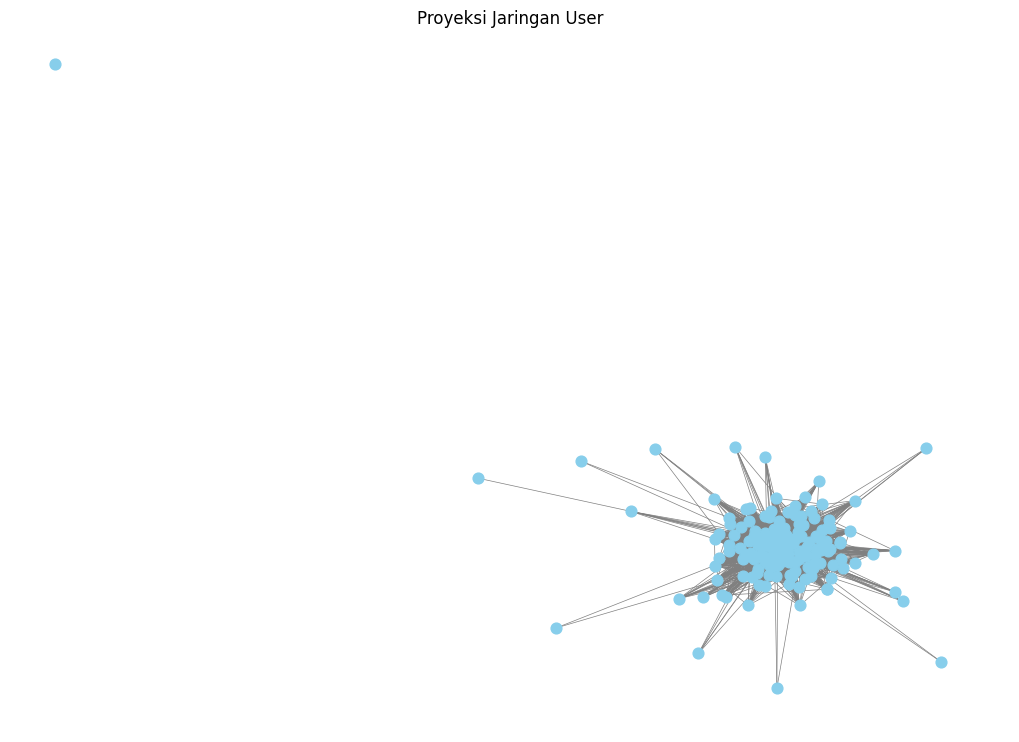

In [26]:
X_user = X_visitor.copy()

print("=== KARAKTERISTIK VSM USER ===")
print("Dimensi:", X_user.ndim)
print("Shape:", X_user.shape)
print("Jumlah User:", X_user.shape[0])
print("Jumlah Item:", X_user.shape[1])
print("Jumlah nilai nonzero:", (X_user.to_numpy() != 0).sum())

print("\nContoh VSM User:")
display(X_user.head())

# Proyeksi graf User:
G_user_projection = nx.bipartite.weighted_projected_graph(
    G_bipartite, user_nodes
)

print("\n=== PROYEKSI USER ===")
print("Jumlah simpul:", G_user_projection.number_of_nodes())
print("Jumlah edge:", G_user_projection.number_of_edges())

# Visualisasi
plt.figure(figsize=(10, 7))

# Batasi simpul yang digambar, bukan data VSM
nodes = list(G_user_projection.nodes())[:200]
G_user_plot = G_user_projection.subgraph(nodes)

pos = nx.spring_layout(G_user_plot, seed=42, iterations=20)

nx.draw(
    G_user_plot,
    pos,
    with_labels=False,
    node_color="skyblue",
    node_size=60,
    edge_color="gray",
    width=0.5
)

plt.title("Proyeksi Jaringan User")
plt.axis("off")
plt.show()


## VSM Item dan proyeksi graf

=== KARAKTERISTIK VSM ITEM ===
Dimensi: 2
Shape: (22479, 200)
Jumlah Item: 22479
Jumlah User: 200
Jumlah nilai nonzero: 43319

Contoh VSM Item:


visitor_id,6170,6958,9535,12579,21395,33604,38015,48820,54791,57905,...,1336835,1343677,1348163,1356496,1357576,1376763,1381830,1384823,1385073,1403769
item_id,,,,,,,,,,,,,,,,,,,,,
15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
66,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Rata-rata interaksi per Item: 4.351216691133947
Interaksi terbanyak: 591.0
Interaksi tersedikit: 1.0



=== PROYEKSI ITEM ===
Jumlah Item: 200
Jumlah edge: 12970


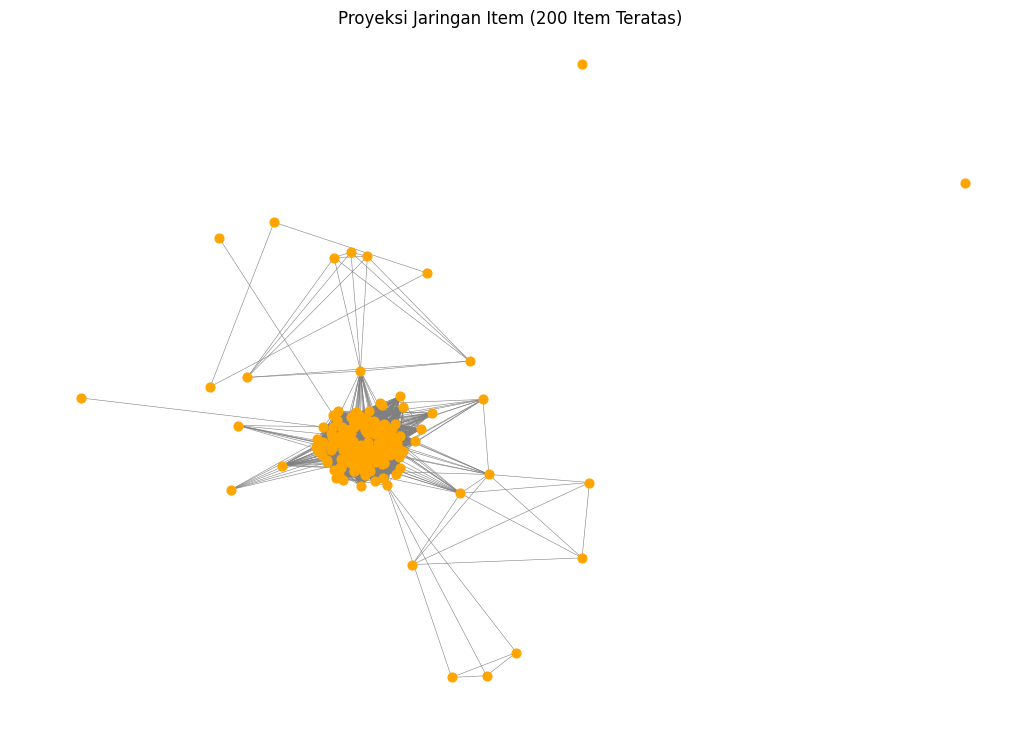

In [27]:
X_item = X_visitor.T

print("=== KARAKTERISTIK VSM ITEM ===")
print("Dimensi:", X_item.ndim)
print("Shape:", X_item.shape)
print("Jumlah Item:", X_item.shape[0])
print("Jumlah User:", X_item.shape[1])
print("Jumlah nilai nonzero:", (X_item.to_numpy() != 0).sum())

print("\nContoh VSM Item:")
display(X_item.head())

# Statistik interaksi Item
jumlah_interaksi_item = X_item.sum(axis=1)

print("\nRata-rata interaksi per Item:",
      jumlah_interaksi_item.mean())
print("Interaksi terbanyak:", jumlah_interaksi_item.max())
print("Interaksi tersedikit:", jumlah_interaksi_item.min())

# Proyeksi graf Item yang lebih ringan
# Pilih 200 Item dengan interaksi terbanyak
top_items = jumlah_interaksi_item.nlargest(200).index
top_item_nodes = [f"Item_{i}" for i in top_items]

# Gunakan subgraf bipartit untuk Item terpilih
G_bipartite_subset = G_bipartite.subgraph(
    user_nodes + top_item_nodes
)

G_item_projection = nx.bipartite.weighted_projected_graph(
    G_bipartite_subset,
    top_item_nodes
)

print("\n=== PROYEKSI ITEM ===")
print("Jumlah Item:", G_item_projection.number_of_nodes())
print("Jumlah edge:", G_item_projection.number_of_edges())

# Visualisasi jaringan Item
plt.figure(figsize=(10, 7))

pos = nx.spring_layout(
    G_item_projection,
    seed=42,
    iterations=10
)

nx.draw(
    G_item_projection,
    pos,
    with_labels=False,
    node_color="orange",
    node_size=40,
    edge_color="gray",
    width=0.4
)

plt.title("Proyeksi Jaringan Item (200 Item Teratas)")
plt.axis("off")
plt.show()


## Membandingkan proyeksi

Visitor-projection membantu menemukan pengunjung dengan pola interaksi serupa; item-projection membantu menemukan produk yang berinteraksi dengan pengunjung yang sama. Gunakan angka hasil eksekusi untuk membahas dimensi matriks, jumlah node/edge, dan efisiensi. Tidak ada proyeksi yang otomatis selalu lebih baik.

In [29]:
hasil_perbandingan = []

G_bipartite_subset = G_bipartite.subgraph(
    user_nodes + top_item_nodes
)

for nama, nodes in [
    ("Proyeksi User", user_nodes),
    ("Proyeksi Item", top_item_nodes)
]:
    waktu_pengukuran = []

    for _ in range(5):
        start = time.perf_counter()

        G_projection = nx.bipartite.weighted_projected_graph(
            G_bipartite_subset, nodes
        )

        waktu_pengukuran.append(time.perf_counter() - start)

    jumlah_simpul = G_projection.number_of_nodes()
    jumlah_edge = G_projection.number_of_edges()

    hasil_perbandingan.append({
        "Karakteristik": nama,
        "Jumlah simpul": jumlah_simpul,
        "Jumlah edge": jumlah_edge,
        "Kepadatan graf": nx.density(G_projection),
        "Rata-rata derajat": (
            sum(dict(G_projection.degree()).values()) / jumlah_simpul
            if jumlah_simpul > 0 else 0
        ),
        "Waktu pembentukan": np.mean(waktu_pengukuran)
    })

df_perbandingan = pd.DataFrame(hasil_perbandingan).set_index(
    "Karakteristik"
).T

df_perbandingan.columns = ["Proyeksi User", "Proyeksi Item"]

display(df_perbandingan.round(5))

,Proyeksi User,Proyeksi Item
Jumlah simpul,200.00000,200.00000
Jumlah edge,5433.00000,12970.00000
Kepadatan graf,0.27302,0.65176
Rata-rata derajat,54.33000,129.70000
Waktu pembentukan,1.20588,0.86332


## Similarity Visitor, lima pasangan teratas, dan update Neo4j

In [31]:
from itertools import combinations
import math

LIMIT_VISITORS = 200

# Memilih 200 pengunjung dengan jumlah item interaksi terbanyak
query_visitors = '''
MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH v, count(DISTINCT i) AS item_count
ORDER BY item_count DESC, v.visitorId
LIMIT $limit
RETURN v.visitorId AS visitor_id
'''

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        selected_for_similarity = [
            r["visitor_id"]
            for r in session.run(
                query_visitors, limit=LIMIT_VISITORS
            )
        ]

# Mengambil interaksi berbobot hanya dari 200 pengunjung terpilih
query_all = '''
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE v.visitorId IN $visitors
RETURN
    v.visitorId AS visitor_id,
    i.itemId AS item_id,
    max(
        CASE type(r)
            WHEN 'VIEWED' THEN 1
            WHEN 'ADDED_TO_CART' THEN 3
            WHEN 'BOUGHT' THEN 5
        END
    ) AS weight
'''

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        records = [
            dict(r) for r in session.run(
                query_all, visitors=selected_for_similarity
            )
        ]

# Membentuk vektor item berbobot untuk setiap pengunjung
visitor_vectors = {}

for row in records:
    visitor_vectors.setdefault(row["visitor_id"], {})
    item_id = row["item_id"]
    weight = row["weight"]

    visitor_vectors[row["visitor_id"]][item_id] = max(
        visitor_vectors[row["visitor_id"]].get(item_id, 0),
        weight
    )

similarity_pairs = []

# Menghitung Cosine Similarity setiap pasangan pengunjung
for a, b in combinations(visitor_vectors, 2):
    vector_a = visitor_vectors[a]
    vector_b = visitor_vectors[b]

    common_items = vector_a.keys() & vector_b.keys()

    dot_product = sum(
        vector_a[item] * vector_b[item]
        for item in common_items
    )

    norm_a = math.sqrt(
        sum(weight ** 2 for weight in vector_a.values())
    )
    norm_b = math.sqrt(
        sum(weight ** 2 for weight in vector_b.values())
    )

    if norm_a > 0 and norm_b > 0:
        score = dot_product / (norm_a * norm_b)

        if score > 0:
            similarity_pairs.append({
                "visitor_a": a,
                "visitor_b": b,
                "similarity": float(score)
            })

similarity_pairs.sort(
    key=lambda x: x["similarity"],
    reverse=True
)

top5_pairs = similarity_pairs[:5]

print("Jumlah pengunjung:", len(visitor_vectors))
print("Jumlah pasangan yang diperiksa:",
      len(visitor_vectors) * (len(visitor_vectors) - 1) // 2)
print("Jumlah pasangan dengan similarity > 0:",
      len(similarity_pairs))
print("Lima pasangan similarity tertinggi (Cosine Similarity):")

display(pd.DataFrame(top5_pairs))


Jumlah pengunjung: 200
Jumlah pasangan yang diperiksa: 19900
Jumlah pasangan dengan similarity > 0: 10106
Lima pasangan similarity tertinggi (Cosine Similarity):


,visitor_a,visitor_b,similarity
0,917504,1119917,0.294671
1,518659,1336835,0.293480
2,524146,1176826,0.291267
3,317355,360921,0.278605
4,590943,856874,0.269892


### Cypher: lima pasangan similarity tertinggi

In [32]:
query_top_similarity = '''
MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
WHERE a.visitorId < b.visitorId
RETURN
    a.visitorId AS visitor_a,
    b.visitorId AS visitor_b,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
'''

print(query_top_similarity)



MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
WHERE a.visitorId < b.visitorId
RETURN
    a.visitorId AS visitor_a,
    b.visitorId AS visitor_b,
    r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5



### Graf sebelum similarity

Graf sebelum similarity — node: 964 | edge: 1000


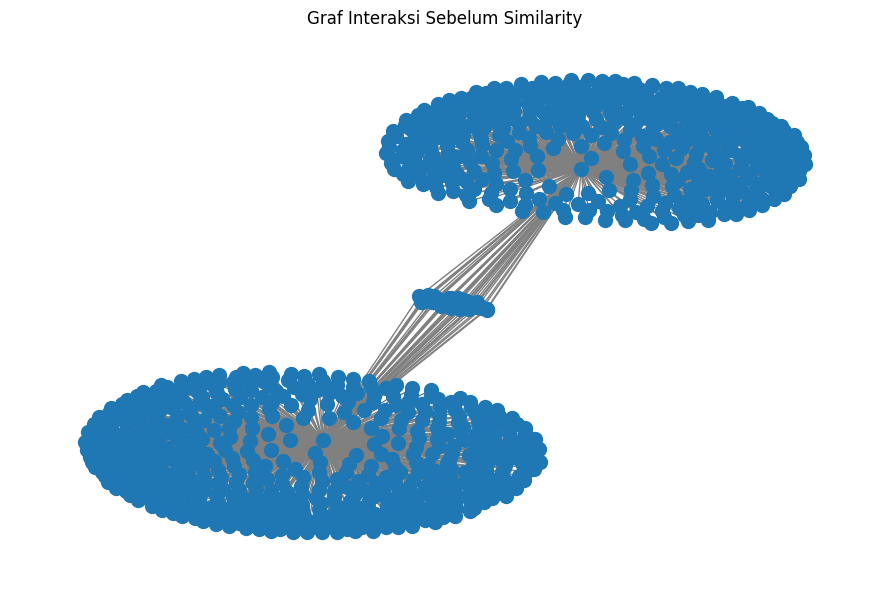

In [33]:

# Graf interaksi Visitor-Item sebelum SIMILAR_TO ditambahkan
before_graph = nx.Graph()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        before_records = [
            dict(r) for r in session.run(
                '''
                MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
                WHERE v.visitorId IN $visitors
                RETURN DISTINCT
                    v.visitorId AS visitor_id,
                    i.itemId AS item_id
                LIMIT 1000
                ''',
                visitors=selected_for_similarity[:30]
            )
        ]

for row in before_records:
    before_graph.add_edge(
        f"V:{row['visitor_id']}",
        f"I:{row['item_id']}"
    )

print(
    "Graf sebelum similarity — node:",
    before_graph.number_of_nodes(),
    "| edge:",
    before_graph.number_of_edges()
)

plt.figure(figsize=(9, 6))
pos_before = nx.spring_layout(before_graph, seed=42)

nx.draw_networkx(
    before_graph,
    pos_before,
    with_labels=False,
    node_size=100,
    edge_color="gray"
)

plt.title("Graf Interaksi Sebelum Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()


### 10c. Simpan hingga 1.000 pasangan dan jalankan query

In [52]:

top_pairs_to_save = similarity_pairs[:1000]

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:

        # Menghapus relasi SIMILAR_TO sebelumnya
        session.run(
            "MATCH ()-[r:SIMILAR_TO]-() DELETE r"
        ).consume()

        # Menyimpan maksimal 1000 pasangan similarity
        if top_pairs_to_save:
            session.run(
                """
                UNWIND $pairs AS pair
                MATCH (a:Visitor {visitorId: pair.visitor_a})
                MATCH (b:Visitor {visitorId: pair.visitor_b})
                MERGE (a)-[r:SIMILAR_TO]-(b)
                SET r.similarity = pair.similarity
                """,
                pairs=top_pairs_to_save
            ).consume()

        saved_count = session.run(
            """
            MATCH ()-[r:SIMILAR_TO]-()
            RETURN count(DISTINCT r) AS jumlah
            """
        ).single()["jumlah"]

        # Mengambil lima pasangan similarity tertinggi
        query_top_similarity = """
        MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
        WHERE a <> b
        WITH DISTINCT
            CASE
                WHEN toString(a.visitorId) < toString(b.visitorId)
                THEN a.visitorId ELSE b.visitorId
            END AS visitor_a,
            CASE
                WHEN toString(a.visitorId) < toString(b.visitorId)
                THEN b.visitorId ELSE a.visitorId
            END AS visitor_b,
            r.similarity AS similarity
        RETURN visitor_a, visitor_b, similarity
        ORDER BY similarity DESC
        LIMIT 5
        """

        top5_db = [
            dict(r)
            for r in session.run(query_top_similarity)
        ]

print("Relasi SIMILAR_TO tersimpan:", saved_count)
print("Lima pasangan similarity tertinggi dari Neo4j:")
display(pd.DataFrame(top5_db))


Relasi SIMILAR_TO tersimpan: 1000
Lima pasangan similarity tertinggi dari Neo4j:


,visitor_a,visitor_b,similarity
0,1119917,917504,0.294671
1,1336835,518659,0.293480
2,1176826,524146,0.291267
3,317355,360921,0.278605
4,590943,856874,0.269892


### Graf setelah similarity

Graf similarity setelah update — node: 42 | edge: 30


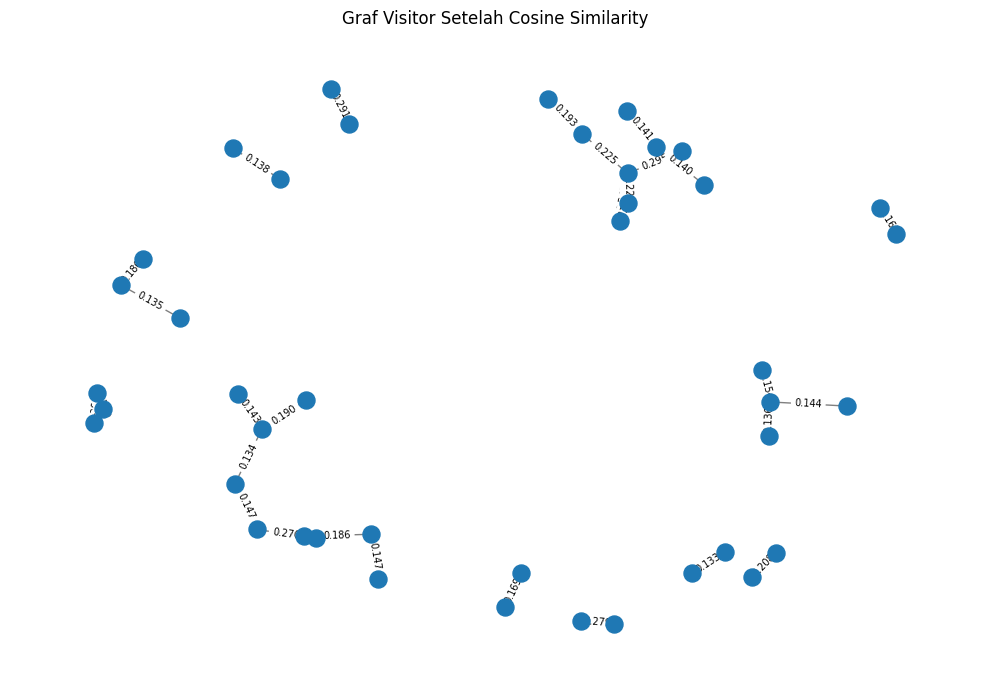

In [35]:

after_graph = nx.Graph()

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database=DATABASE) as session:
        after_records = [
            dict(r) for r in session.run(
                '''
                MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
                WHERE a.visitorId < b.visitorId
                RETURN
                    a.visitorId AS visitor_a,
                    b.visitorId AS visitor_b,
                    r.similarity AS similarity
                ORDER BY similarity DESC
                LIMIT 30
                '''
            )
        ]

for row in after_records:
    after_graph.add_edge(
        row["visitor_a"],
        row["visitor_b"],
        weight=row["similarity"]
    )

print(
    "Graf similarity setelah update — node:",
    after_graph.number_of_nodes(),
    "| edge:",
    after_graph.number_of_edges()
)

plt.figure(figsize=(10, 7))
pos_after = nx.spring_layout(after_graph, seed=42)

nx.draw_networkx(
    after_graph,
    pos_after,
    with_labels=False,
    node_size=150,
    edge_color="gray"
)

edge_labels = {
    (u, v): f"{data['weight']:.3f}"
    for u, v, data in after_graph.edges(data=True)
}

nx.draw_networkx_edge_labels(
    after_graph,
    pos_after,
    edge_labels=edge_labels,
    font_size=7
)

plt.title("Graf Visitor Setelah Cosine Similarity")
plt.axis("off")
plt.tight_layout()
plt.show()


## Analytics: KNN dengan k=5, rekomendasi tiga item, Hit@5 dan NDCG@5

User dipilih secara acak tetapi dapat direproduksi menggunakan seed tetap. P1 menjadi training, P2 menjadi testing. Hasil evaluasi bisa bernilai 0 jika rekomendasi tidak cocok dengan item P2; jangan memilih user berdasarkan hasil evaluasi karena itu membuat evaluasi bias.

In [36]:
train = pd.read_csv(P1_FILE)
test = pd.read_csv(P2_FILE)

print("Kolom train:", train.columns.tolist())
print("Kolom test:", test.columns.tolist())

display(train.head())


Kolom train: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
Kolom test: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [ ]:
start = time.time()
rng = np.random.default_rng(42)

In [41]:
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

In [43]:
# ==========================================
# 1. PERSIAPAN DATA
# ==========================================
train = train.rename(columns={
    "visitorid": "visitor_id",
    "itemid": "item_id"
}).copy()

test = test.rename(columns={
    "visitorid": "visitor_id",
    "itemid": "item_id"
}).copy()

assert {"visitor_id", "item_id"}.issubset(train.columns)
assert {"visitor_id", "item_id"}.issubset(test.columns)

# Pembobotan interaksi jika jenis event tersedia
event_col = next(
    (c for c in ["event", "event_type"] if c in train.columns),
    None
)

if event_col:
    event_weights = {
        "view": 1,
        "viewed": 1,
        "addtocart": 3,
        "add_to_cart": 3,
        "added_to_cart": 3,
        "transaction": 5,
        "bought": 5,
        "purchase": 5,
        "purchased": 5
    }

    event_names = (
        train[event_col]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )

    train["interaction"] = event_names.map(event_weights)

    unknown_events = event_names[train["interaction"].isna()].unique()

    if len(unknown_events) > 0:
        raise ValueError(
            f"Jenis event belum memiliki bobot: {unknown_events.tolist()}"
        )

    interactions = (
        train.groupby(["visitor_id", "item_id"])["interaction"]
        .sum()
        .reset_index()
    )

    print("Pembobotan event digunakan:", event_col)
else:
    # Alternatif jika data tidak memiliki kolom jenis event
    interactions = (
        train.groupby(["visitor_id", "item_id"])
        .size()
        .reset_index(name="interaction")
    )

    print(
        "Kolom event tidak tersedia. "
        "Frekuensi interaksi digunakan sebagai bobot."
    )

# Batas komputasi
MAX_CANDIDATE_USERS = 3000
MAX_EVAL_USERS = 100
K = 5
TOP_N = 5
TOP_ADS = 3

# Memilih user yang memiliki minimal 2 item berbeda di train
user_counts = interactions.groupby("visitor_id")["item_id"].nunique()
active_users = user_counts[user_counts >= 2].index.to_numpy()

if len(active_users) < 2:
    raise ValueError("Jumlah user aktif di train tidak mencukupi.")

candidate_users = rng.choice(
    active_users,
    size=min(MAX_CANDIDATE_USERS, len(active_users)),
    replace=False
)

candidate_set = set(candidate_users)

interactions = interactions[
    interactions["visitor_id"].isin(candidate_set)
].copy()

user_ids = pd.Index(candidate_users)
item_ids = pd.Index(interactions["item_id"].unique())

user_to_idx = {u: i for i, u in enumerate(user_ids)}
item_to_idx = {item: i for i, item in enumerate(item_ids)}

rows = interactions["visitor_id"].map(user_to_idx).to_numpy()
cols = interactions["item_id"].map(item_to_idx).to_numpy()
values = interactions["interaction"].to_numpy(dtype=np.float32)

# Matriks user-item hanya dibentuk dari train
user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.float32
)

print("Jumlah kandidat user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Jumlah interaksi user-item:", user_item_matrix.nnz)

Pembobotan event digunakan: event
Jumlah kandidat user: 3000
Jumlah item: 8905
Jumlah interaksi user-item: 10946


In [44]:
# ==========================================
# 2. MENYIAPKAN RELEVANSI DARI TEST
# ==========================================
test_subset = test[
    test["visitor_id"].isin(candidate_set)
    & test["item_id"].isin(item_to_idx)
]

test_relevant = {}

for user, group in test_subset.groupby("visitor_id"):
    uidx = user_to_idx[user]
    seen = set(user_item_matrix[uidx].indices)

    relevant = {
        item_to_idx[item]
        for item in group["item_id"].unique()
        if item_to_idx[item] not in seen
    }

    if relevant:
        test_relevant[uidx] = relevant

eligible = np.array(list(test_relevant.keys()), dtype=int)

if len(eligible) == 0:
    raise ValueError(
        "Tidak ada user evaluasi yang memenuhi syarat. "
        "Periksa pembagian train-test dan ketersediaan item."
    )

eval_users = rng.choice(
    eligible,
    size=min(MAX_EVAL_USERS, len(eligible)),
    replace=False
)

# Satu user acak yang dapat direproduksi untuk laporan
selected_user = int(rng.choice(eval_users))

print("Jumlah user evaluasi:", len(eval_users))
print("User terpilih untuk analisis:", user_ids[selected_user])

Jumlah user evaluasi: 36
User terpilih untuk analisis: 95611


In [45]:
# ==========================================
# 3. FIT KNN PADA DATA TRAIN
# ==========================================
knn = NearestNeighbors(
    n_neighbors=min(K + 1, len(user_ids)),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)

knn.fit(user_item_matrix)

print("KNN selesai fit.")

KNN selesai fit.


In [47]:
# ==========================================
# 4. SKOR POPULARITAS DARI TRAIN
# ==========================================
popularity = np.asarray(
    user_item_matrix.sum(axis=0)
).ravel().astype(np.float32)

In [48]:
# ==========================================
# 5. REKOMENDASI DAN EVALUASI
# ==========================================
results = []

for uidx in eval_users:
    # Mencari tetangga terdekat
    distances, neighbors = knn.kneighbors(
        user_item_matrix[uidx],
        return_distance=True
    )

    neighbor_ids = []
    similarities = []

    for neighbor, distance in zip(neighbors[0], distances[0]):
        if neighbor == uidx:
            continue

        neighbor_ids.append(int(neighbor))
        similarities.append(max(0.0, 1.0 - float(distance)))

        if len(neighbor_ids) >= K:
            break

    # Skor item berdasarkan interaksi tetangga berbobot similarity
    if neighbor_ids:
        scores = np.asarray(
            user_item_matrix[neighbor_ids].T.dot(
                np.asarray(similarities, dtype=np.float32)
            )
        ).ravel()
    else:
        scores = np.zeros(len(item_ids), dtype=np.float32)

    # Item yang sudah berinteraksi dengan user tidak direkomendasikan
    seen = user_item_matrix[uidx].indices
    scores[seen] = -np.inf

    # Fallback jika tidak ada skor rekomendasi positif
    fallback_popularity = not np.any(scores > 0)

    if fallback_popularity:
        scores = popularity.copy()
        scores[seen] = -np.inf

    # Mengambil Top-5 dengan skor tertinggi
    top_indices = np.argsort(-scores, kind="stable")[:TOP_N]
    top_indices = [
        int(i) for i in top_indices if np.isfinite(scores[i])
    ]

    relevant = test_relevant[uidx]

    # Relevansi biner untuk setiap peringkat Top-5
    relevance_at_k = [
        int(item in relevant) for item in top_indices
    ]

    # Hit@5
    hit_at_5 = int(any(relevance_at_k))

    # NDCG@5
    dcg = sum(
        rel / np.log2(rank + 2)
        for rank, rel in enumerate(relevance_at_k)
    )

    ideal_count = min(len(relevant), TOP_N)

    idcg = sum(
        1 / np.log2(rank + 2)
        for rank in range(ideal_count)
    )

    ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

    results.append({
        "visitor_id": user_ids[uidx],
        "recommendations": [
            item_ids[i] for i in top_indices
        ],
        "advertised_items": [
            item_ids[i] for i in top_indices[:TOP_ADS]
        ],
        "jumlah_tetangga": len(neighbor_ids),
        "fallback_popularity": fallback_popularity,
        "Hit@5": hit_at_5,
        "NDCG@5": ndcg_at_5
    })

In [49]:
# ==========================================
# 6. HASIL EVALUASI
# ==========================================
hasil = pd.DataFrame(results)

print("\n===== HASIL EVALUASI KNN =====")
print("User dievaluasi:", len(hasil))
print(f"Hit@5 rata-rata  : {hasil['Hit@5'].mean():.4f}")
print(f"NDCG@5 rata-rata : {hasil['NDCG@5'].mean():.4f}")
print(f"Waktu total      : {time.time() - start:.2f} detik")

display(
    hasil.drop(columns=["recommendations", "advertised_items"])
    .head(10)
)



===== HASIL EVALUASI KNN =====
User dievaluasi: 36
Hit@5 rata-rata  : 0.0556
NDCG@5 rata-rata : 0.0195
Waktu total      : 233.86 detik


,visitor_id,jumlah_tetangga,fallback_popularity,Hit@5,NDCG@5
0,1296963,5,False,0,0.000000
1,412312,5,False,0,0.000000
2,809264,5,False,0,0.000000
3,155590,5,False,0,0.000000
4,197192,5,False,0,0.000000
5,118662,5,True,0,0.000000
6,1110880,5,True,0,0.000000
7,328629,5,True,0,0.000000
8,648787,5,False,1,0.386853
9,684770,5,False,0,0.000000


In [50]:
# ==========================================
# 7. HASIL USER TERPILIH DAN TIGA ITEM IKLAN
# ==========================================
hasil_user = hasil[
    hasil["visitor_id"] == user_ids[selected_user]
].iloc[0]

print("\n===== HASIL USER TERPILIH =====")
print("Visitor ID:", hasil_user["visitor_id"])
print("Jumlah tetangga yang digunakan:", hasil_user["jumlah_tetangga"])
print("Menggunakan fallback popularitas:", hasil_user["fallback_popularity"])

print("\nLima rekomendasi KNN:")
display(pd.DataFrame({
    "peringkat": range(1, len(hasil_user["recommendations"]) + 1),
    "item_id": hasil_user["recommendations"]
}))

print("\nTiga item yang diiklankan:")
display(pd.DataFrame({
    "peringkat_iklan": range(1, len(hasil_user["advertised_items"]) + 1),
    "item_id": hasil_user["advertised_items"]
}))

print("\nEvaluasi user terpilih:")
print(f"Hit@5  : {hasil_user['Hit@5']:.4f}")
print(f"NDCG@5 : {hasil_user['NDCG@5']:.4f}")



===== HASIL USER TERPILIH =====
Visitor ID: 95611
Jumlah tetangga yang digunakan: 5
Menggunakan fallback popularitas: False

Lima rekomendasi KNN:


,peringkat,item_id
0,1,464998
1,2,12492
2,3,358180
3,4,89639
4,5,262699



Tiga item yang diiklankan:


,peringkat_iklan,item_id
0,1,464998
1,2,12492
2,3,358180



Evaluasi user terpilih:
Hit@5  : 0.0000
NDCG@5 : 0.0000



# A. Wrangling dan Eksplorasi Graf

## 1. Menentukan Dua Periode Waktu

**Jawaban:**

Periode waktu yang digunakan untuk membagi data interaksi adalah:

- **P1 (Training):** 31 Mei 2015 sampai 31 Juli 2015.
- **P2 (Testing):** 9 Agustus 2015 sampai 24 Agustus 2015.

Batas akhir dibuat eksklusif, yaitu P1 sebelum 1 Agustus 2015 dan P2 sebelum 25 Agustus 2015. Timestamp pada dataset menggunakan satuan milidetik.

## 2. Filter Timestamp dan Penyimpanan CSV

**Jawaban:**

Filter timestamp dilakukan menggunakan Python dan Pandas dengan metode chunking sebanyak 200.000 baris setiap prosesnya agar penggunaan memori lebih hemat.

Hasil filter disimpan ke dalam dua file:

- `data/events_p1.csv` untuk data training.
- `data/events_p2.csv` untuk data testing.

Berdasarkan hasil eksekusi notebook, jumlah data yang tersimpan adalah 1.324.774 baris untuk P1 dan 279.544 baris untuk P2.

## 3. Komposisi Subgraph Menggunakan Python API

**Jawaban:**

Komposisi subgraph diperiksa menggunakan query Cypher yang dijalankan melalui Python API Neo4j. Hasilnya sebagai berikut.

| Elemen | Jumlah |
|---|---:|
| Simpul Visitor | 684.227 |
| Simpul Item | 171.126 |
| Relasi VIEWED | 1.281.023 |
| Relasi ADDED_TO_CART | 32.807 |
| Relasi BOUGHT | 10.944 |
| Total relasi | 1.324.774 |

Query Cypher yang digunakan untuk menghitung simpul Visitor:

```cypher
MATCH (v:Visitor)
RETURN count(v) AS jumlah;
```

Untuk menghitung simpul Item, label `Visitor` diganti menjadi `Item`.

Query untuk menghitung relasi VIEWED:

```cypher
MATCH ()-[r:VIEWED]->()
RETURN count(r) AS jumlah;
```

Query serupa digunakan untuk relasi ADDED_TO_CART dan BOUGHT. Query dijalankan melalui `session.run(query).single()["jumlah"]` pada Python.

## 4. VSM terhadap Simpul User

**Jawaban:**

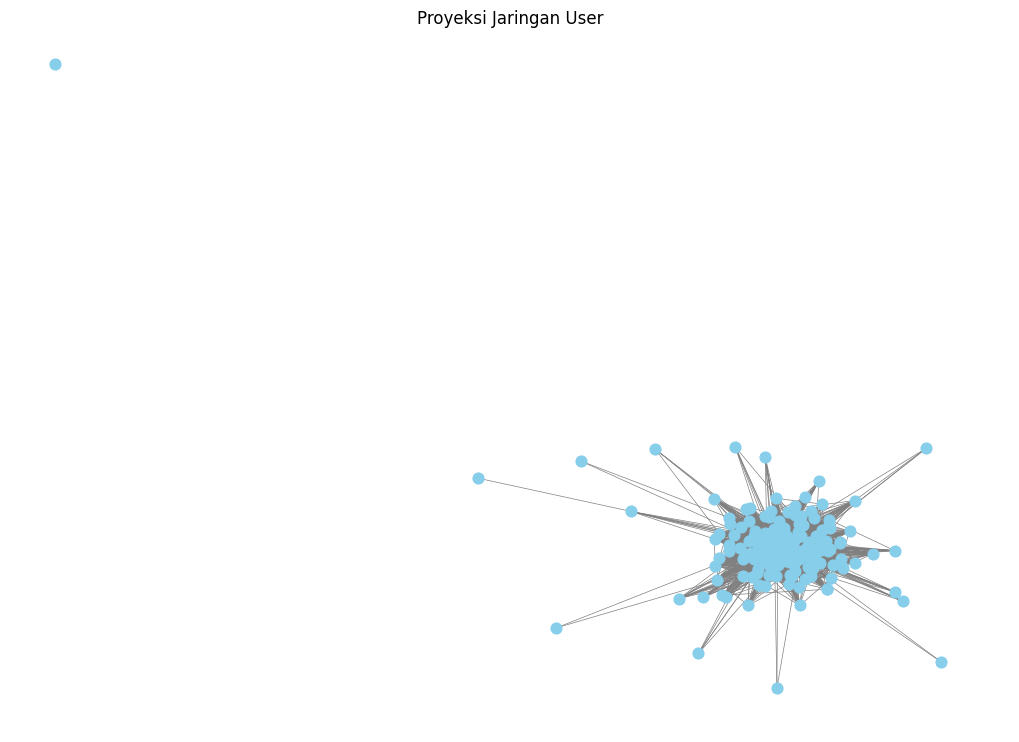
*Vector Space Model* (VSM) User dibentuk dari graf bipartit Visitor–Item. Baris mewakili Visitor (User), kolom mewakili Item, dan nilai sel adalah total bobot interaksi Visitor terhadap Item tersebut. Bobot interaksi: `VIEWED = 1`, `ADDED_TO_CART = 3`, dan `BOUGHT = 5`, lalu dijumlahkan jika ada beberapa interaksi pada pasangan yang sama. Untuk menjaga komputasi tetap ringan, hanya **200 Visitor dengan jumlah relasi terbanyak** yang dipakai.

| Karakteristik | Nilai |
|---|---:|
| Dimensi (ndim) | 2 (matriks) |
| Bentuk matriks (User × Item) | 200 × 22.479 |
| Jumlah User (baris) | 200 |
| Jumlah Item (kolom) | 22.479 |
| Jumlah nilai nonzero | 43.319 |
| Kepadatan (nonzero / total sel) | ≈ 0,96% (sparsity ≈ 99,04%) |

Karakteristik penting:
- Matriks **sangat sparse**: sebagian besar User hanya berinteraksi dengan sebagian kecil dari 22.479 Item.
- Setiap vektor baris adalah profil preferensi satu User, sehingga kedekatan antar User dapat diukur dengan *cosine similarity*.

**Proyeksi graf User.** Graf bipartit berisi 22.679 simpul (200 User + 22.479 Item) dan 43.319 edge. Proyeksi pada himpunan User menghasilkan graf dengan **200 simpul dan 9.202 edge** (kepadatan ≈ 0,462; rata-rata derajat ≈ 92,0). Dua User terhubung jika pernah berinteraksi dengan minimal satu Item yang sama, dan bobot edge adalah jumlah Item yang dibagi bersama. Visualisasinya menunjukkan jaringan yang cukup rapat dengan beberapa User berperan sebagai penghubung.

## 5. VSM terhadap Simpul Item

**Jawaban:**

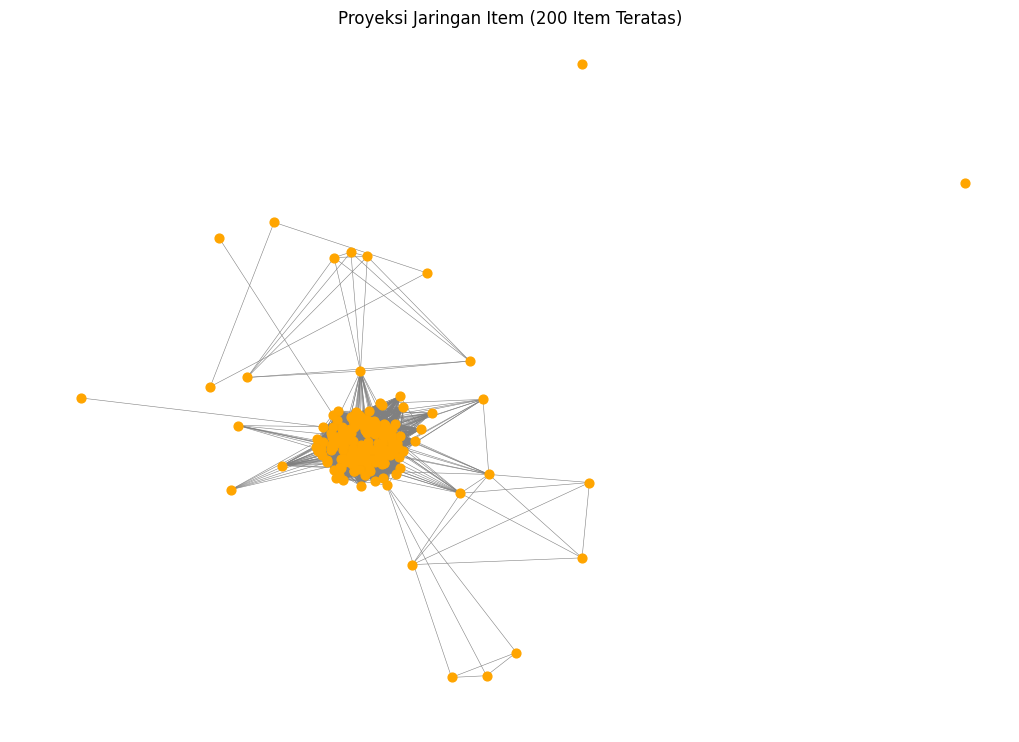
VSM Item adalah **transpos** dari VSM User: baris mewakili Item, kolom mewakili Visitor, dan nilainya tetap total bobot interaksi yang sama.

| Karakteristik | Nilai |
|---|---:|
| Dimensi (ndim) | 2 (matriks) |
| Bentuk matriks (Item × User) | 22.479 × 200 |
| Jumlah Item (baris) | 22.479 |
| Jumlah User (kolom) | 200 |
| Jumlah nilai nonzero | 43.319 (sama dengan VSM User) |
| Rata-rata bobot interaksi per Item | ≈ 4,35 |
| Bobot interaksi terbanyak | 591 |
| Bobot interaksi tersedikit | 1 |

Karakteristik penting:
- Sparsity sama dengan VSM User (≈ 99,04%) karena isinya identik.
- Distribusinya *long-tail*: rata-rata hanya ≈ 4,35 sementara maksimumnya 591, artinya sebagian besar Item hanya disentuh satu atau sedikit User, sedangkan segelintir Item sangat populer.
- Vektor baris menggambarkan "profil pengunjung" sebuah Item, sehingga kedekatan antar Item dapat diukur dari kesamaan pengunjungnya.

**Proyeksi graf Item.** Karena seluruh 22.479 Item terlalu berat diproyeksikan, proyeksi dibatasi pada **200 Item dengan interaksi terbanyak**. Hasilnya graf dengan **200 simpul dan 12.970 edge**. Dua Item terhubung jika dikunjungi/dibeli oleh minimal satu User yang sama (bobot edge = jumlah User yang sama).

## 6. Perbandingan Proyeksi User dan Item

**Jawaban:**

Agar perbandingannya adil, kedua proyeksi dibentuk dari subgraf bipartit yang sama (200 User + 200 Item teratas) dan waktu pembentukan dirata-ratakan dari 5 kali percobaan.

| Karakteristik | Proyeksi User | Proyeksi Item |
|---|---:|---:|
| Jumlah simpul | 200 | 200 |
| Jumlah edge | 5.433 | 12.970 |
| Kepadatan graf | 0,27302 | 0,65176 |
| Rata-rata derajat | 54,33 | 129,70 |
| Waktu pembentukan (detik) | 1,20588 | 0,86332 |

Analisis:
- **Kepadatan.** Proyeksi Item jauh lebih padat (0,652 vs 0,273). Item populer dikunjungi banyak User sehingga mudah terhubung lewat pengunjung bersama, sedangkan User hanya terhubung bila beririsan pada Item yang sama di antara 200 Item teratas.
- **Waktu.** Pembentukan proyeksi Item sedikit lebih cepat (0,86 s vs 1,21 s). Selisihnya kecil karena jumlah simpul sama, dan hasil ini bisa dipengaruhi kondisi komputasi.
- **Catatan angka.** Proyeksi User pada seluruh 22.479 Item (bagian 4) punya 9.202 edge, sedangkan pada subset 200 Item teratas hanya 5.433 edge. Selisih ini wajar karena irisan Item antar User berkurang ketika Item yang dipertimbangkan dipangkas.
- **Pemilihan.** Tidak ada yang otomatis lebih baik. Proyeksi User cocok untuk *user-based collaborative filtering* (mencari pengunjung sepola), sedangkan proyeksi Item cocok untuk *item-based* (mencari produk yang sering dikunjungi orang yang sama). Proyeksi Item lebih padat sehingga lebih mahal untuk analisis lanjutan, sementara proyeksi User lebih ringan untuk tujuan rekomendasi pada tugas ini.

## 7. Menghitung Similarity pada Graf Terproyeksi

**Jawaban:**

Similarity dihitung dengan **Cosine Similarity** pada graf proyeksi User. Setiap Visitor direpresentasikan sebagai vektor Item berbobot (`VIEWED = 1`, `ADDED_TO_CART = 3`, `BOUGHT = 5`, memakai bobot tertinggi per Item). Dari 200 Visitor dengan jumlah Item berbeda terbanyak, diperiksa **19.900 pasangan**, dan **10.106 pasangan** memiliki similarity > 0. Nilai tertinggi hanya sekitar 0,29, menandakan tumpang tindih Item antar pengunjung kecil (data sangat sparse).

> Catatan: 200 Visitor di tahap ini dipilih berdasarkan jumlah Item berbeda, sedangkan VSM sebelumnya berdasarkan jumlah relasi, sehingga himpunannya bisa tidak persis sama.

### (a) Lima Pasangan dengan Similarity Tertinggi

Query Cypher berikut digunakan untuk memperoleh lima pasangan *Visitor* dengan nilai similarity tertinggi berdasarkan relasi `SIMILAR_TO` yang telah tersimpan pada graf Neo4j.

```cypher
MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
WHERE a <> b
WITH DISTINCT
    CASE
        WHEN toString(a.visitorId) < toString(b.visitorId)
        THEN a.visitorId
        ELSE b.visitorId
    END AS visitor_a,
    CASE
        WHEN toString(a.visitorId) < toString(b.visitorId)
        THEN b.visitorId
        ELSE a.visitorId
    END AS visitor_b,
    r.similarity AS similarity
RETURN visitor_a, visitor_b, similarity
ORDER BY similarity DESC
LIMIT 5;
```

### (b) Menyimpan Nilai Similarity pada Graf Neo4j

**Hasil query:**

| No. | Visitor A | Visitor B | Similarity |
|---:|---:|---:|---:|
| 1 | 1119917 | 917504 | 0.294671 |
| 2 | 1336835 | 518659 | 0.293480 |
| 3 | 1176826 | 524146 | 0.291267 |
| 4 | 317355 | 360921 | 0.278605 |
| 5 | 590943 | 856874 | 0.269892 |

Berdasarkan hasil tersebut, pasangan `Visitor` dengan ID 1119917 dan 917504 memiliki nilai similarity tertinggi, yaitu 0.294671.


## 8. Kondisi Graf Sebelum dan Sesudah Similarity

**Jawaban:**

### Sebelum

MATCH (v:Visitor)-[r]-(i:Item)
RETURN v, r, i
LIMIT 50;

![alt text](<sebelum similarity.svg>)

### Sesudah

MATCH (a:Visitor)-[r:SIMILAR_TO]-(b:Visitor)
RETURN a, r, b
ORDER BY r.similarity DESC
LIMIT 20;

![alt text](<setelah similarity.svg>)


# B. Analytics

## 1. Rekomendasi Menggunakan KNN dengan K = 5

**Jawaban:**

Model KNN dilatih dari data **P1** (training), lalu hasil rekomendasi diuji terhadap data **P2** (testing). Ruang pencarian: 3.000 User kandidat yang dipilih acak (seed 42) dari User dengan minimal 2 Item berbeda di P1, dengan 8.905 Item dan 10.946 interaksi User–Item. Bobot interaksi tetap `view = 1`, `addtocart = 3`, `transaction = 5`.

### (a) Skrip Python KNN

```python
from sklearn.neighbors import NearestNeighbors

K = 5
TOP_N = 5
TOP_ADS = 3

# 1. Melatih KNN hanya pada data train (P1)
knn = NearestNeighbors(
    n_neighbors=min(K + 1, len(user_ids)),
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
knn.fit(user_item_matrix)

# 2. Mencari 5 tetangga terdekat (User target dikeluarkan)
distances, neighbors = knn.kneighbors(
    user_item_matrix[uidx], return_distance=True
)
neighbor_ids, similarities = [], []
for neighbor, distance in zip(neighbors[0], distances[0]):
    if neighbor == uidx:
        continue
    neighbor_ids.append(int(neighbor))
    similarities.append(max(0.0, 1.0 - float(distance)))
    if len(neighbor_ids) >= K:
        break

# 3. Skor Item = interaksi tetangga x similarity
scores = np.asarray(
    user_item_matrix[neighbor_ids].T.dot(
        np.asarray(similarities, dtype=np.float32)
    )
).ravel()

# 4. Item yang sudah pernah diakses User tidak direkomendasikan
seen = user_item_matrix[uidx].indices
scores[seen] = -np.inf

# 5. Fallback ke popularitas jika tidak ada skor positif
if not np.any(scores > 0):
    scores = popularity.copy()
    scores[seen] = -np.inf

# 6. Ambil Top-5 rekomendasi, Top-3 untuk iklan
top_indices = np.argsort(-scores, kind="stable")[:TOP_N]
advertised = top_indices[:TOP_ADS]
```

Cara kerja singkat: tetangga = User dengan *cosine distance* terkecil, tiap tetangga dibobot dengan similarity-nya (`1 − distance`), dan Item dengan skor gabungan tertinggi yang belum pernah diakses User menjadi rekomendasi.

### (b) Tiga Item Rekomendasi

User terpilih (acak, seed 42, dari 36 User yang memenuhi syarat evaluasi): **Visitor 95611**, dengan 5 tetangga dan tanpa fallback popularitas.

Lima rekomendasi KNN:

| Peringkat | Item ID |
|---:|---:|
| 1 | 464998 |
| 2 | 12492 |
| 3 | 358180 |
| 4 | 89639 |
| 5 | 262699 |

Tiga Item yang diiklankan (Top-3):

| Peringkat Iklan | Item ID |
|---:|---:|
| 1 | 464998 |
| 2 | 12492 |
| 3 | 358180 |


## 2. Evaluasi Rekomendasi dengan Hit@5 dan NDCG@5

**Jawaban:**
Item relevan adalah Item yang muncul pada data **P2** untuk User tersebut, berada dalam himpunan Item training, dan belum pernah diakses di P1. Evaluasi dilakukan pada **36 User** yang memiliki Item relevan (target 100 User, tetapi hanya 36 yang memenuhi syarat).

| Metrik | User terpilih (95611) | Rata-rata 36 User |
|---|---:|---:|
| Hit@5 | 0,0000 | 0,0556 |
| NDCG@5 | 0,0000 | 0,0195 |

### (a) Hit@5

$$\text{Hit@5} = \begin{cases} 1 & \text{jika ada minimal satu Item relevan di Top-5} \\ 0 & \text{jika tidak ada} \end{cases}$$

- Untuk Visitor 95611, tidak ada Item di Top-5 yang muncul pada P2, sehingga **Hit@5 = 0**.
- Rata-rata **Hit@5 = 0,0556** berarti 2 dari 36 User (≈ 5,6%) mendapat minimal satu rekomendasi yang tepat.

### (b) NDCG@5

$$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i+1)}, \qquad \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

dengan $rel_i = 1$ jika Item peringkat ke-$i$ relevan dan 0 jika tidak, serta IDCG@5 adalah DCG pada urutan ideal.

- Untuk Visitor 95611, **NDCG@5 = 0** karena tidak ada Item relevan di Top-5.
- Rata-rata **NDCG@5 = 0,0195**. Contoh: Visitor 648787 mendapat NDCG@5 ≈ 0,387, yaitu satu Item relevan tepat di peringkat 5 (1/log₂6).

**Interpretasi.** Nilai kedua metrik rendah, tetapi wajar karena:
- Interaksi sangat sparse (≈ 99%) dan tiap User hanya sedikit Item relevan di P2.
- Hanya 3.000 User kandidat dan 5 tetangga yang dipakai, sehingga tetangga jarang memiliki Item yang sama dengan perilaku masa depan User.
- Sebagian User (3 dari 10 contoh pertama) memakai *fallback* popularitas karena tetangganya tidak memberi skor positif.
- Item relevan di P2 dihitung dari semua jenis event (termasuk sekadar *view*), sementara jeda waktu P1–P2 membuat selera User bisa berubah.

Hasil ini dapat diperbaiki dengan menambah jumlah tetangga/User kandidat, memakai *item-based* atau hybrid dengan popularitas, serta menyaring event menjadi hanya `addtocart`/`transaction` sebagai target relevan.
